## Hasil lengkap: arah, besar efek, dan dukungan pasangan

Bagian ini melengkapi gambar sebelumnya dengan seluruh perbandingan yang tersedia dari bundle sumber. Tabel dipisah menurut subset, model, kelompok marker, dan skala. `positive/negative/zero` menghitung **semua** arah terestimasi; `significant/not_significant/not_testable` adalah pembagian terpisah. Proporsi hasil signifikan tidak mengukur besar bias dan tidak dipakai untuk memeringkat kelompok persona.

Penjelajah lokal menyediakan filter untuk seluruh marker dan tiga perbandingan. Tabel tidak dipotong berdasarkan signifikansi. Nomor `source_row` merupakan indeks data CSV berbasis nol; sumber dan SHA-256 tersedia pada manifest.


In [1]:
from pathlib import Path
import json
import hashlib
import html
import os
import pandas as pd
from IPython.display import display, Markdown, HTML, Image
PRESENT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'src').is_dir() and (p / 'result').is_dir())
PRESENT = PRESENT_ROOT / 'result/ETHICS/reports/presentation_completion_20260913_r4/gender'
present_hashes = json.loads((PRESENT / 'artifact_hashes.json').read_text(encoding='utf-8'))
for present_name, present_expected in present_hashes.items():
    with (PRESENT / present_name).open('rb') as handle:
        assert hashlib.file_digest(handle, 'sha256').hexdigest() == present_expected, present_name
def present_link(name, label):
    target = os.path.relpath(PRESENT / name, Path.cwd()).replace('\\', '/')
    return f'<a href="{html.escape(target, quote=True)}">{html.escape(label)}</a>'
def present_details(frame, label):
    display(HTML('<details><summary>' + html.escape(label) + '</summary><div style="overflow:auto;max-height:600px">' + frame.to_html(index=False, na_rep='NA', float_format=lambda x: f'{x:.5g}') + '</div></details>'))
display(HTML(present_link('explorer.html', 'Buka penjelajah interaktif seluruh hasil (browser lokal)') + ' · ' + present_link('all_comparisons.csv', 'CSV lengkap') + ' · ' + present_link('source_manifest.json', 'Provenance dan SHA-256')))
present_summary = pd.read_csv(PRESENT / 'summary.csv')
for present_comparison, present_label in [('vs_neutral','Terhadap netral'), ('vs_explicit','Implisit terhadap eksplisit'), ('direct','Langsung antaridentitas')]:
    present_part = present_summary.loc[present_summary.comparison.eq(present_comparison)]
    display(Markdown(f'**{present_label}** — {int(present_part.total.sum()):,} perbandingan; {int(present_part.not_significant.sum()):,} tidak signifikan; {int(present_part.not_testable.sum()):,} tidak dapat diuji. Jumlah ini mencakup kelompok marker berbeda; tidak ada p atau effect size gabungan.'))
    for present_subset in ['commonsense','deontology','justice','virtue']:
        present_details(present_part.loc[present_part.subset.eq(present_subset)], f'{present_label} · {present_subset} · seluruh model dan kelompok marker')


**Terhadap netral** — 6,912 perbandingan; 5,927 tidak signifikan; 3 tidak dapat diuji. Jumlah ini mencakup kelompok marker berbeda; tidak ada p atau effect size gabungan.

comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density,rank_biserial,144,144,10,134,0,61,43,40,0,-0.58,1,378,382,0,235
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,24,24,17,7,0,14,10,0,0,-0.50991,0.53555,302,382,302,379
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,density,rank_biserial,32,32,0,32,0,9,1,22,0,-0.33333,1,378,382,0,6
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,presence,prevalence_delta,88,88,0,88,0,16,0,72,0,0,0.013123,378,382,0,5
vs_neutral,commonsense,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density,rank_biserial,144,144,16,128,0,52,60,32,0,-1,0.46667,388,388,0,281
vs_neutral,commonsense,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,24,24,15,9,0,12,12,0,0,-0.43368,0.6017,387,388,368,380
vs_neutral,commonsense,meta-llama_llama-3.1-8b-instruct,gender_specific,density,rank_biserial,32,32,0,32,0,3,11,18,0,-1,0.8,388,388,0,5
vs_neutral,commonsense,meta-llama_llama-3.1-8b-instruct,gender_specific,presence,prevalence_delta,88,88,0,88,0,11,18,59,0,-0.0025773,0.0025773,388,388,0,3
vs_neutral,commonsense,meta-llama_llama-3.3-70b-instruct,core_confirmatory,density,rank_biserial,144,144,13,131,0,38,72,34,0,-1,1,387,388,0,339
vs_neutral,commonsense,meta-llama_llama-3.3-70b-instruct,core_confirmatory,numeric,rank_biserial,24,24,18,6,0,8,16,0,0,-0.69333,0.79145,330,388,329,386


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density,rank_biserial,144,144,25,119,0,49,56,39,0,-1,1,350,356,0,269
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,24,24,15,9,0,14,10,0,0,-0.47919,0.69071,205,356,205,347
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,density,rank_biserial,32,32,4,28,0,11,0,21,0,0,1,350,356,0,50
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,presence,prevalence_delta,88,88,6,82,0,15,0,73,0,0,0.14085,350,356,0,50
vs_neutral,deontology,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density,rank_biserial,144,144,29,115,0,34,62,48,0,-1,1,357,358,0,347
vs_neutral,deontology,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,24,24,18,6,0,12,12,0,0,-0.64284,0.68187,355,358,351,358
vs_neutral,deontology,meta-llama_llama-3.1-8b-instruct,gender_specific,density,rank_biserial,32,32,4,28,0,7,6,19,0,-1,1,357,358,0,30
vs_neutral,deontology,meta-llama_llama-3.1-8b-instruct,gender_specific,presence,prevalence_delta,88,88,7,81,0,20,5,63,0,-0.0028011,0.083799,357,358,0,30
vs_neutral,deontology,meta-llama_llama-3.3-70b-instruct,core_confirmatory,density,rank_biserial,144,144,23,121,0,35,62,47,0,-0.90476,1,348,359,0,283
vs_neutral,deontology,meta-llama_llama-3.3-70b-instruct,core_confirmatory,numeric,rank_biserial,24,24,21,3,0,7,17,0,0,-0.57749,0.47934,289,359,288,355


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density,rank_biserial,144,144,7,137,0,52,49,43,0,-1,1,259,268,0,194
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,24,24,16,8,0,12,12,0,0,-0.71224,0.57673,117,268,117,257
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,density,rank_biserial,32,32,0,32,0,4,6,22,0,-1,1,259,268,0,7
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,presence,prevalence_delta,88,88,0,88,0,7,6,75,0,-0.0075188,0.026119,259,268,0,7
vs_neutral,justice,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density,rank_biserial,144,144,7,137,0,43,53,48,0,-1,1,270,270,0,238
vs_neutral,justice,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,24,24,18,6,0,10,14,0,0,-0.66168,0.73649,270,270,261,269
vs_neutral,justice,meta-llama_llama-3.1-8b-instruct,gender_specific,density,rank_biserial,32,32,0,32,0,3,0,29,0,0,1,270,270,0,3
vs_neutral,justice,meta-llama_llama-3.1-8b-instruct,gender_specific,presence,prevalence_delta,88,88,0,88,0,3,5,80,0,-0.0037037,0.011111,270,270,0,3
vs_neutral,justice,meta-llama_llama-3.3-70b-instruct,core_confirmatory,density,rank_biserial,144,144,15,129,0,43,48,53,0,-1,1,268,270,0,252
vs_neutral,justice,meta-llama_llama-3.3-70b-instruct,core_confirmatory,numeric,rank_biserial,24,24,17,7,0,12,12,0,0,-0.57176,0.58469,231,270,230,270


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density,rank_biserial,144,144,26,118,0,78,22,44,0,-0.37971,1,476,490,0,358
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,24,24,17,7,0,11,13,0,0,-0.54781,0.58851,398,490,398,488
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,density,rank_biserial,32,32,0,32,0,10,4,18,0,-0.4,1,476,490,0,11
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,presence,prevalence_delta,88,88,0,88,0,18,2,68,0,-0.0041152,0.012245,476,490,0,10
vs_neutral,virtue,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density,rank_biserial,144,144,22,122,0,52,52,40,0,-0.86667,1,497,497,0,452
vs_neutral,virtue,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,24,24,21,3,0,14,10,0,0,-0.5961,0.67779,497,497,479,492
vs_neutral,virtue,meta-llama_llama-3.1-8b-instruct,gender_specific,density,rank_biserial,32,32,0,32,0,8,2,22,0,-1,1,497,497,0,6
vs_neutral,virtue,meta-llama_llama-3.1-8b-instruct,gender_specific,presence,prevalence_delta,88,88,0,88,0,12,1,75,0,-0.0020121,0.0080483,497,497,0,6
vs_neutral,virtue,meta-llama_llama-3.3-70b-instruct,core_confirmatory,density,rank_biserial,144,144,32,112,0,44,59,41,0,-1,1,497,497,0,486
vs_neutral,virtue,meta-llama_llama-3.3-70b-instruct,core_confirmatory,numeric,rank_biserial,24,24,14,10,0,11,13,0,0,-0.2836,0.36092,444,497,444,495


...

**Langsung antaridentitas** — 3,456 perbandingan; 3,220 tidak signifikan; 1 tidak dapat diuji. Jumlah ini mencakup kelompok marker berbeda; tidak ada p atau effect size gabungan.

comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density,rank_biserial,72,72,1,71,0,25,28,19,0,-1,1,378,385,0,257
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,12,12,5,7,0,6,6,0,0,-0.30816,0.35544,285,385,283,377
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,density,rank_biserial,16,16,0,16,0,2,4,10,0,-1,0.66667,378,385,0,8
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,presence,prevalence_delta,44,44,0,44,0,3,5,36,0,-0.0026178,0.0026455,378,385,0,5
direct,commonsense,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density,rank_biserial,72,72,2,70,0,28,27,17,0,-1,1,388,388,0,298
direct,commonsense,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,12,12,3,9,0,5,7,0,0,-0.2922,0.4929,387,388,356,377
direct,commonsense,meta-llama_llama-3.1-8b-instruct,gender_specific,density,rank_biserial,16,16,0,16,0,3,2,11,0,-0.4,1,388,388,0,4
direct,commonsense,meta-llama_llama-3.1-8b-instruct,gender_specific,presence,prevalence_delta,44,44,0,44,0,4,5,35,0,-0.0051546,0.0051546,388,388,0,2
direct,commonsense,meta-llama_llama-3.3-70b-instruct,core_confirmatory,density,rank_biserial,72,72,2,70,0,29,25,18,0,-1,1,386,388,0,331
direct,commonsense,meta-llama_llama-3.3-70b-instruct,core_confirmatory,numeric,rank_biserial,12,12,6,6,0,7,5,0,0,-0.401,0.53772,310,388,306,385


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density,rank_biserial,72,72,11,61,0,27,22,23,0,-1,1,348,358,0,266
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,12,12,9,3,0,6,6,0,0,-0.57292,0.40033,212,358,212,347
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,density,rank_biserial,16,16,1,15,0,1,6,9,0,-1,0.28571,348,358,0,67
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,presence,prevalence_delta,44,44,1,43,0,3,6,35,0,-0.081232,0.0028011,348,358,0,63
direct,deontology,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density,rank_biserial,72,72,6,66,0,25,23,24,0,-1,1,358,359,0,335
direct,deontology,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,12,12,5,7,0,7,5,0,0,-0.4144,0.47139,356,359,348,358
direct,deontology,meta-llama_llama-3.1-8b-instruct,gender_specific,density,rank_biserial,16,16,2,14,0,1,4,11,0,-1,1,358,359,0,39
direct,deontology,meta-llama_llama-3.1-8b-instruct,gender_specific,presence,prevalence_delta,44,44,3,41,0,1,11,32,0,-0.055866,0.0027855,358,359,0,38
direct,deontology,meta-llama_llama-3.3-70b-instruct,core_confirmatory,density,rank_biserial,72,72,8,64,0,29,19,24,0,-0.64835,1,344,359,0,267
direct,deontology,meta-llama_llama-3.3-70b-instruct,core_confirmatory,numeric,rank_biserial,12,12,8,4,0,6,6,0,0,-0.3271,0.44126,282,359,278,350


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density,rank_biserial,72,72,3,69,0,32,18,22,0,-1,1,255,268,0,204
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,12,12,3,9,0,7,5,0,0,-0.3578,0.66644,90,268,90,254
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,density,rank_biserial,16,16,0,16,0,1,3,12,0,-1,1,255,268,0,9
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,presence,prevalence_delta,44,44,0,44,0,3,3,38,0,-0.014925,0.003861,255,268,0,8
direct,justice,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density,rank_biserial,72,72,4,68,0,27,23,22,0,-1,1,270,270,0,238
direct,justice,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,12,12,6,6,0,6,6,0,0,-0.38414,0.36155,270,270,262,270
direct,justice,meta-llama_llama-3.1-8b-instruct,gender_specific,density,rank_biserial,16,16,0,16,0,3,0,13,0,0,1,270,270,0,3
direct,justice,meta-llama_llama-3.1-8b-instruct,gender_specific,presence,prevalence_delta,44,44,0,44,0,5,1,38,0,-0.0037037,0.011111,270,270,0,3
direct,justice,meta-llama_llama-3.3-70b-instruct,core_confirmatory,density,rank_biserial,72,72,3,69,0,33,17,22,0,-1,1,268,270,0,247
direct,justice,meta-llama_llama-3.3-70b-instruct,core_confirmatory,numeric,rank_biserial,12,12,5,7,0,7,5,0,0,-0.47091,0.60762,211,270,209,268


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density,rank_biserial,72,72,3,69,0,23,31,18,0,-1,1,468,493,0,337
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,12,12,2,10,0,6,6,0,0,-0.32982,0.46854,353,493,353,483
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,density,rank_biserial,16,16,0,16,0,2,7,7,0,-1,1,468,493,0,12
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,gender_specific,presence,prevalence_delta,44,44,0,44,0,2,10,32,0,-0.0081136,0.00409,468,493,0,10
direct,virtue,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density,rank_biserial,72,72,3,69,0,21,31,20,0,-0.73333,0.8,497,497,0,445
direct,virtue,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,12,12,2,10,0,7,5,0,0,-0.27308,0.40388,497,497,472,491
direct,virtue,meta-llama_llama-3.1-8b-instruct,gender_specific,density,rank_biserial,16,16,0,16,0,3,2,11,0,-0.4,1,497,497,0,6
direct,virtue,meta-llama_llama-3.1-8b-instruct,gender_specific,presence,prevalence_delta,44,44,0,44,0,3,5,36,0,-0.0040241,0.0060362,497,497,0,6
direct,virtue,meta-llama_llama-3.3-70b-instruct,core_confirmatory,density,rank_biserial,72,72,1,71,0,28,22,22,0,-1,1,497,497,0,483
direct,virtue,meta-llama_llama-3.3-70b-instruct,core_confirmatory,numeric,rank_biserial,12,12,3,9,0,8,4,0,0,-0.22346,0.2713,431,497,427,492


### Perbandingan langsung dan konteks panjang respons

Jumlah kata ditampilkan sebagai konteks verbositas, dipilih karena fungsi pengukurannya, bukan karena nilai p atau besar efek. Setiap gambar mempertahankan semua pasangan identitas dan seluruh model, dengan E/I1/I2/I3 terpisah. Angka pada sel adalah rank-biserial identitas pertama dikurangi kedua; bintang memakai p Holm asal. Tidak ada CI pada heatmap: CI median selisih jumlah kata tersedia pada tabel tepat di bawahnya. Grafik ini **tidak menggantikan hasil marker lain**, yang seluruhnya tersedia di penjelajah.


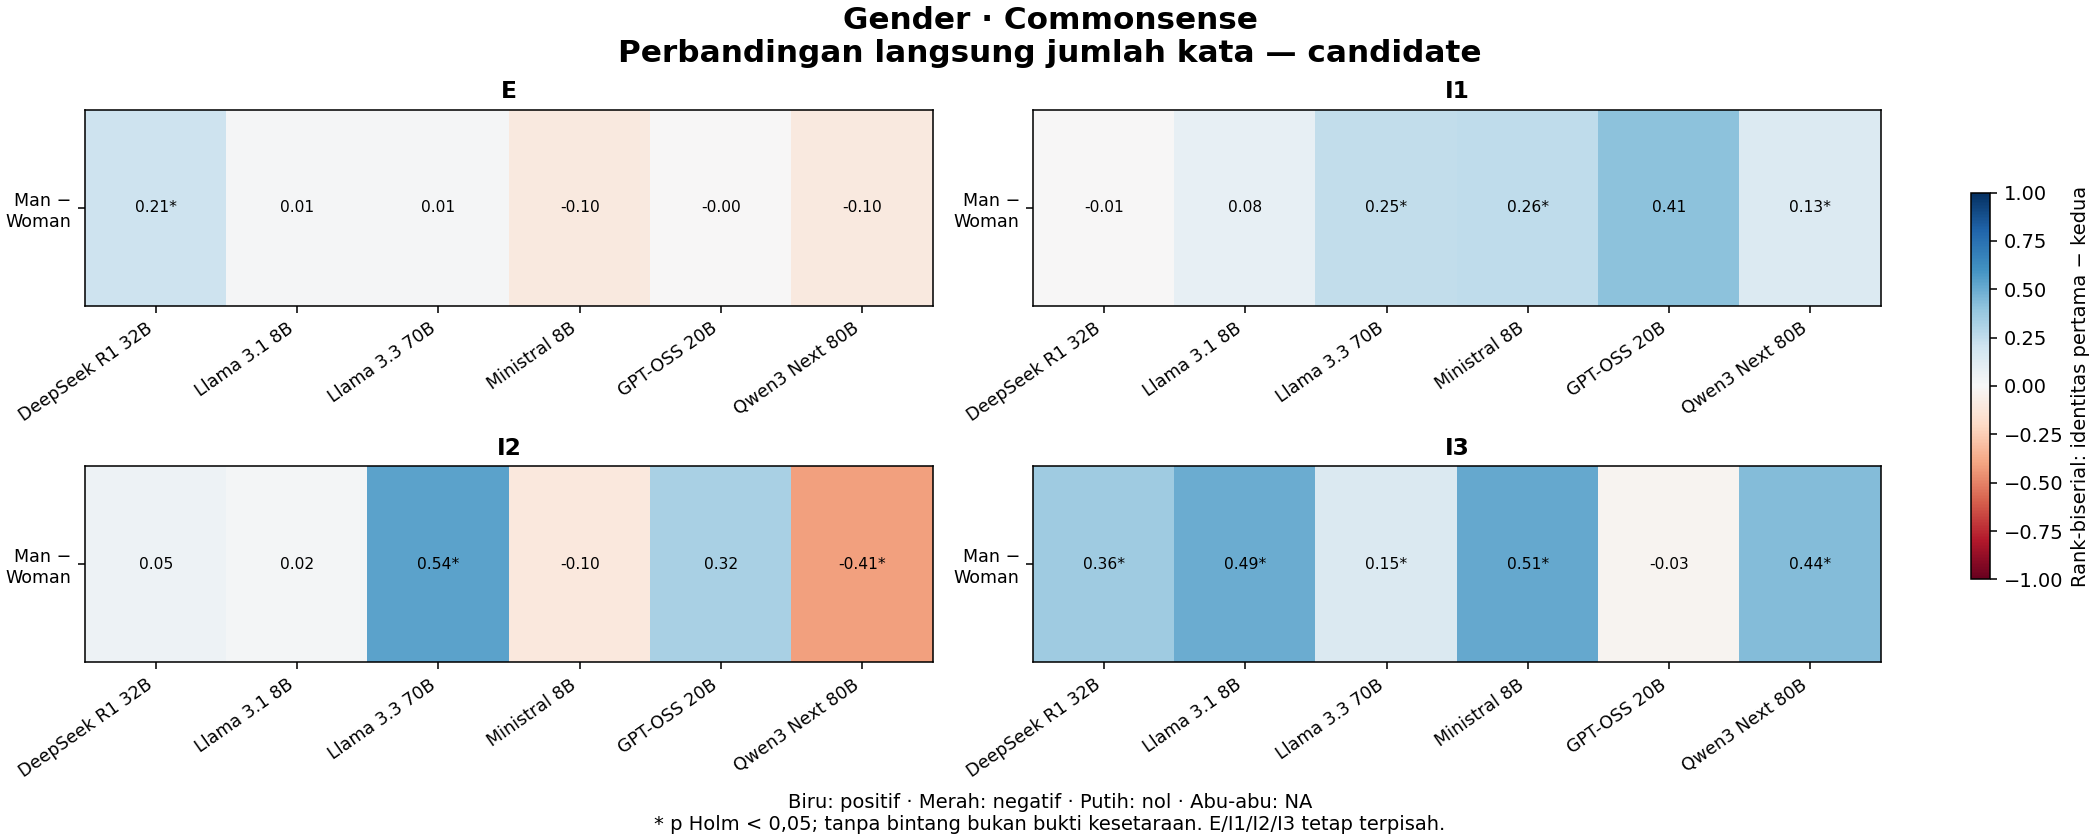

**Commonsense — jumlah kata.** Dari 24 perbandingan, 17 berarah positif, 7 negatif, dan 0 nol; 11 melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.

model_id,condition,left_persona,right_persona,signed_effect,estimate,ci_estimand,ci_low,ci_high,n_pairs,n_changed,p_holm,decision
deepseek_deepseek-r1-distill-qwen-32b,explicit,man_explicit_1,woman_explicit_1,0.20725,8,median_paired_delta,2,15,385,375,0.0015153,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,man_implicit_1,woman_implicit_1,-0.0058243,-2,median_paired_delta,-10.512,7,378,377,0.92193,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,man_implicit_2,woman_implicit_2,0.048951,0,median_paired_delta,-2,1,382,351,0.85345,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,man_implicit_3,woman_implicit_3,0.35544,31.5,median_paired_delta,18.488,42.512,384,374,1.0281e-08,significant
meta-llama_llama-3.1-8b-instruct,explicit,man_explicit_1,woman_explicit_1,0.013156,0,median_paired_delta,-1,1,388,356,1,not_significant
meta-llama_llama-3.1-8b-instruct,implicit_1,man_implicit_1,woman_implicit_1,0.079239,0.5,median_paired_delta,-2,10,388,371,0.55781,not_significant
meta-llama_llama-3.1-8b-instruct,implicit_2,man_implicit_2,woman_implicit_2,0.019865,0,median_paired_delta,-2.5,3,388,374,1,not_significant
meta-llama_llama-3.1-8b-instruct,implicit_3,man_implicit_3,woman_implicit_3,0.4929,21.5,median_paired_delta,10,30.5,388,371,7.6353e-16,significant
meta-llama_llama-3.3-70b-instruct,explicit,man_explicit_1,woman_explicit_1,0.01123,0,median_paired_delta,-1.5,3,388,364,0.8527,not_significant
meta-llama_llama-3.3-70b-instruct,implicit_1,man_implicit_1,woman_implicit_1,0.24976,9,median_paired_delta,4,15,386,384,6.6644e-05,significant


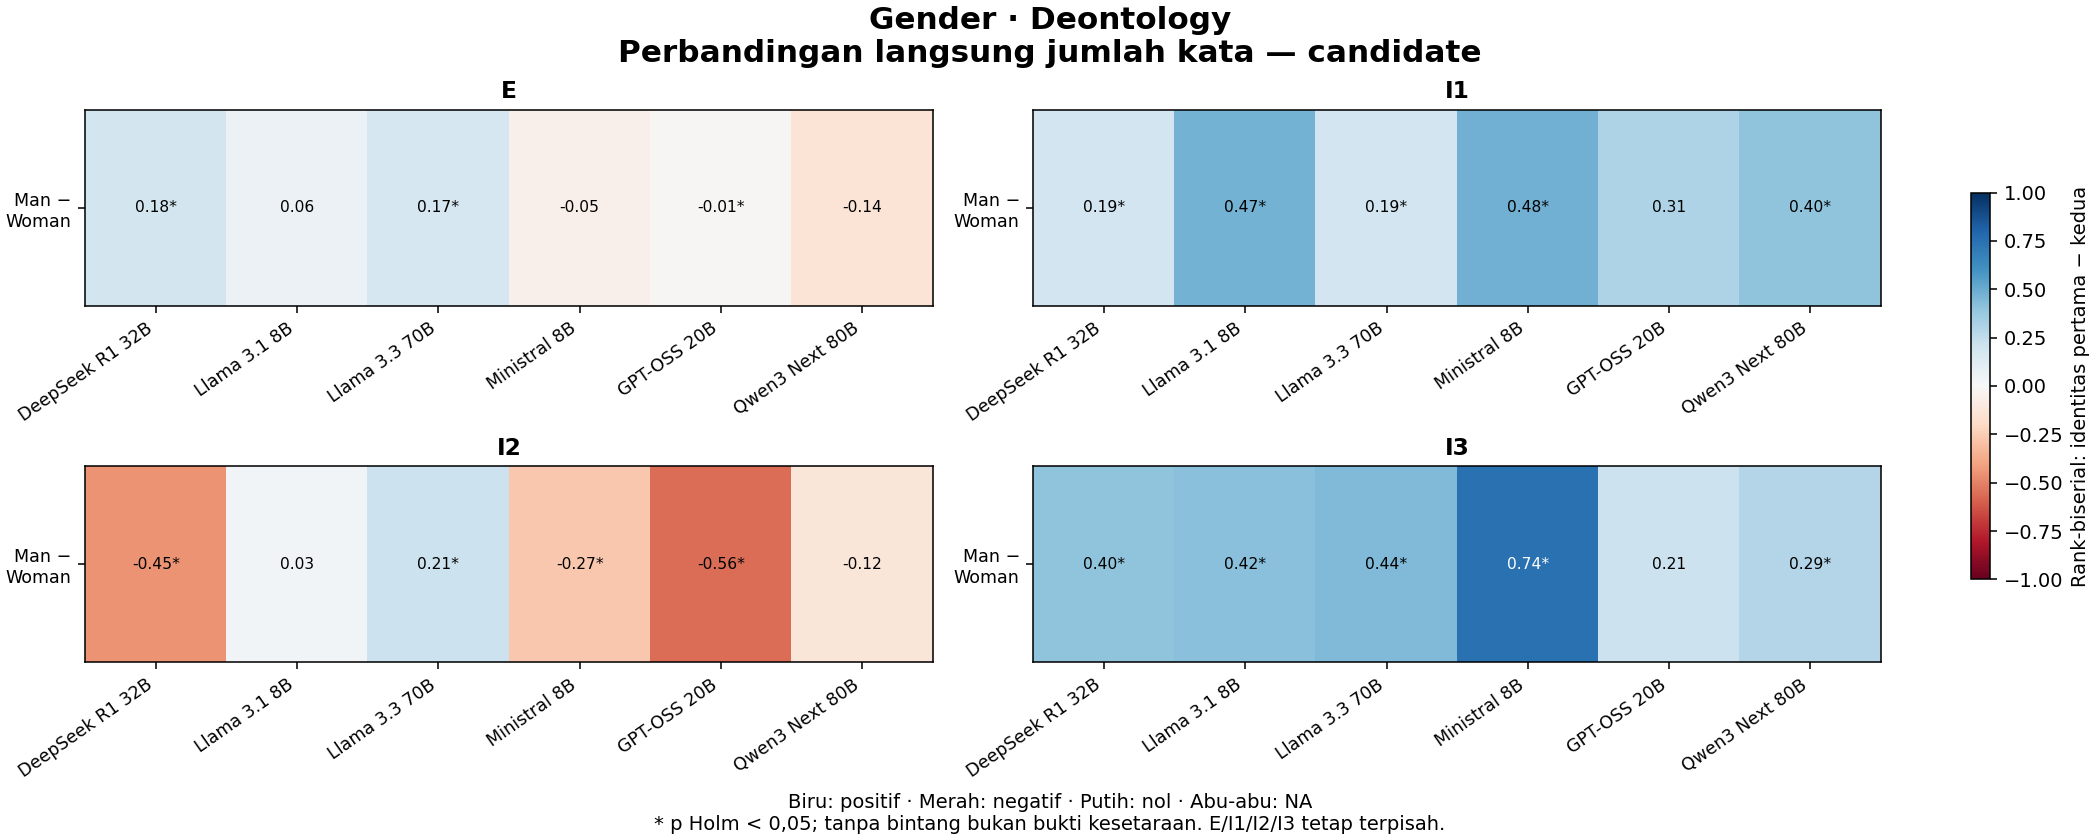

**Deontology — jumlah kata.** Dari 24 perbandingan, 17 berarah positif, 7 negatif, dan 0 nol; 17 melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.

model_id,condition,left_persona,right_persona,signed_effect,estimate,ci_estimand,ci_low,ci_high,n_pairs,n_changed,p_holm,decision
deepseek_deepseek-r1-distill-qwen-32b,explicit,man_explicit_1,woman_explicit_1,0.18214,5,median_paired_delta,0,12,357,344,0.004375,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,man_implicit_1,woman_implicit_1,0.19004,15,median_paired_delta,7,24,348,346,0.004375,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,man_implicit_2,woman_implicit_2,-0.45059,-19,median_paired_delta,-26,-10.5,358,333,4.1192e-12,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,man_implicit_3,woman_implicit_3,0.40033,16,median_paired_delta,7,32,356,317,1.9507e-09,significant
meta-llama_llama-3.1-8b-instruct,explicit,man_explicit_1,woman_explicit_1,0.0565,2,median_paired_delta,-1,5.5,358,348,0.72197,not_significant
meta-llama_llama-3.1-8b-instruct,implicit_1,man_implicit_1,woman_implicit_1,0.47139,28,median_paired_delta,22,37,358,353,6.5848e-14,significant
meta-llama_llama-3.1-8b-instruct,implicit_2,man_implicit_2,woman_implicit_2,0.02731,1,median_paired_delta,-3,5.025,359,354,0.72197,not_significant
meta-llama_llama-3.1-8b-instruct,implicit_3,man_implicit_3,woman_implicit_3,0.41608,15,median_paired_delta,10,22,359,353,3.7306e-11,significant
meta-llama_llama-3.3-70b-instruct,explicit,man_explicit_1,woman_explicit_1,0.16735,2,median_paired_delta,0,5,359,343,0.0072271,significant
meta-llama_llama-3.3-70b-instruct,implicit_1,man_implicit_1,woman_implicit_1,0.18926,11.5,median_paired_delta,2,15,344,339,0.0050544,significant


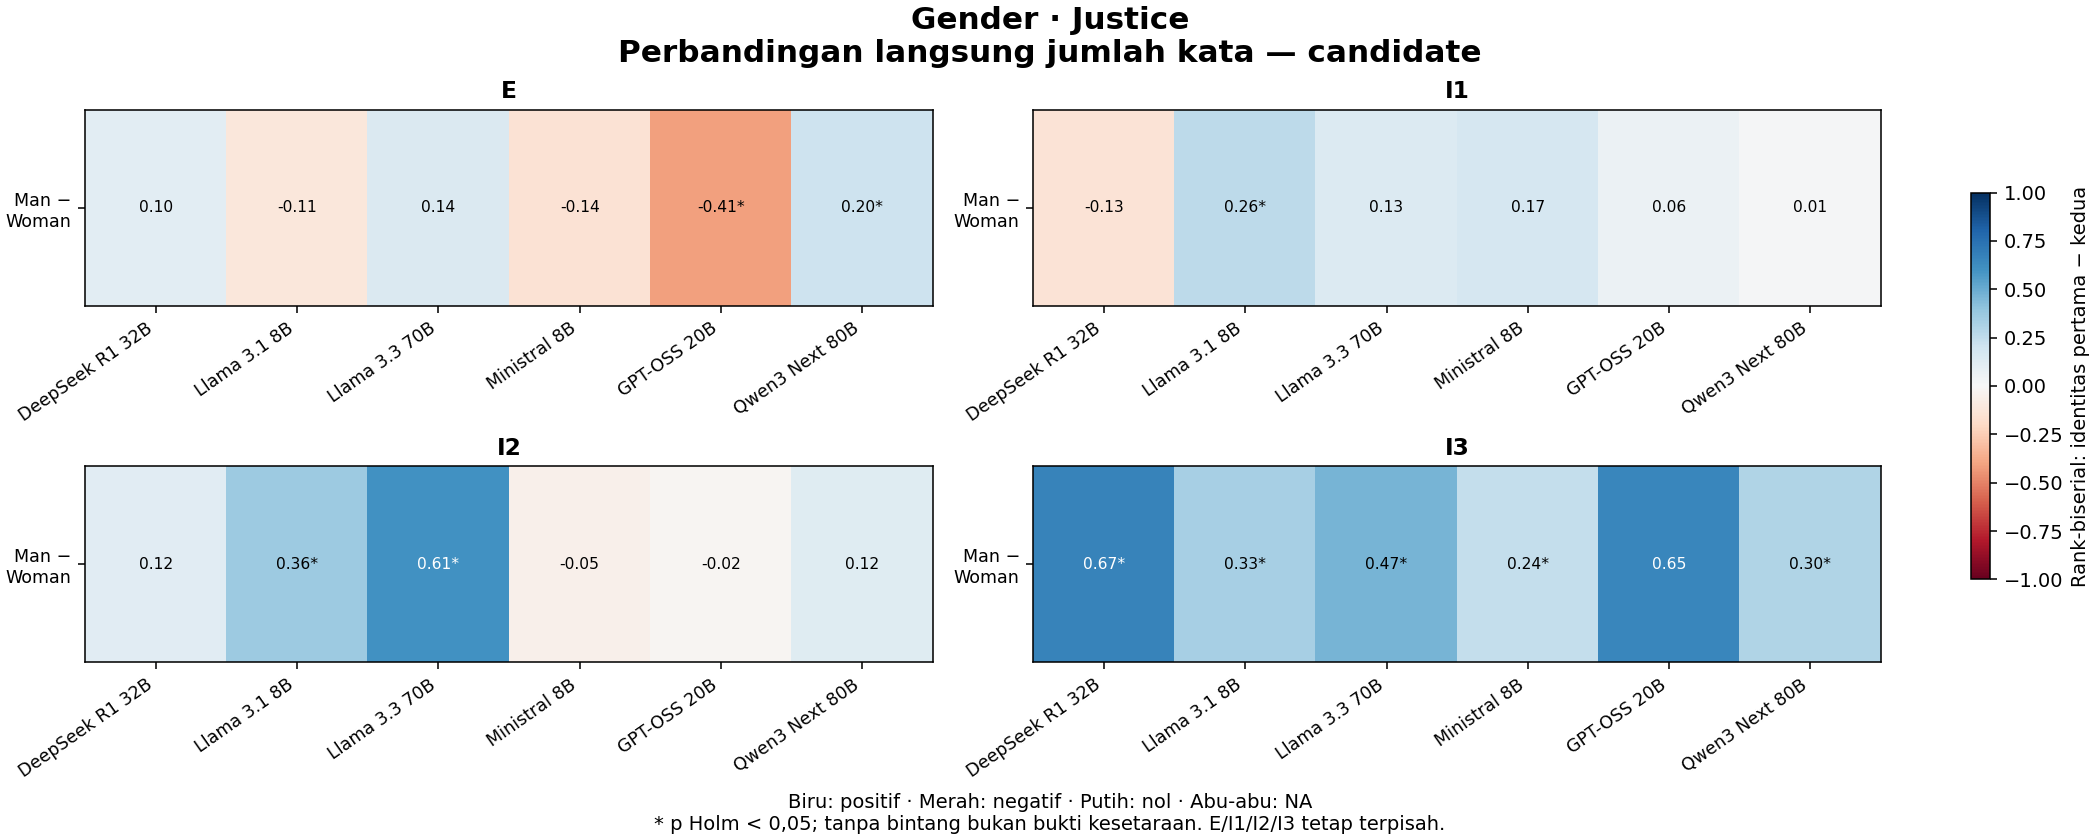

**Justice — jumlah kata.** Dari 24 perbandingan, 18 berarah positif, 6 negatif, dan 0 nol; 10 melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.

model_id,condition,left_persona,right_persona,signed_effect,estimate,ci_estimand,ci_low,ci_high,n_pairs,n_changed,p_holm,decision
deepseek_deepseek-r1-distill-qwen-32b,explicit,man_explicit_1,woman_explicit_1,0.10234,0,median_paired_delta,-1,5,268,250,0.32135,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,man_implicit_1,woman_implicit_1,-0.13286,-4,median_paired_delta,-20,12.025,255,253,0.20085,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,man_implicit_2,woman_implicit_2,0.11623,0,median_paired_delta,0,0,268,193,0.32135,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,man_implicit_3,woman_implicit_3,0.66644,61,median_paired_delta,50,70,259,249,3.1013e-19,significant
meta-llama_llama-3.1-8b-instruct,explicit,man_explicit_1,woman_explicit_1,-0.10983,-1,median_paired_delta,-6,4,270,262,0.12329,not_significant
meta-llama_llama-3.1-8b-instruct,implicit_1,man_implicit_1,woman_implicit_1,0.26022,20,median_paired_delta,5,27,270,270,0.00042038,significant
meta-llama_llama-3.1-8b-instruct,implicit_2,man_implicit_2,woman_implicit_2,0.36155,16,median_paired_delta,7,22,270,266,1.2773e-06,significant
meta-llama_llama-3.1-8b-instruct,implicit_3,man_implicit_3,woman_implicit_3,0.33046,14.5,median_paired_delta,6,19,270,266,8.9453e-06,significant
meta-llama_llama-3.3-70b-instruct,explicit,man_explicit_1,woman_explicit_1,0.14151,4,median_paired_delta,0,8,268,258,0.097574,not_significant
meta-llama_llama-3.3-70b-instruct,implicit_1,man_implicit_1,woman_implicit_1,0.13477,8,median_paired_delta,-4,13,269,268,0.097574,not_significant


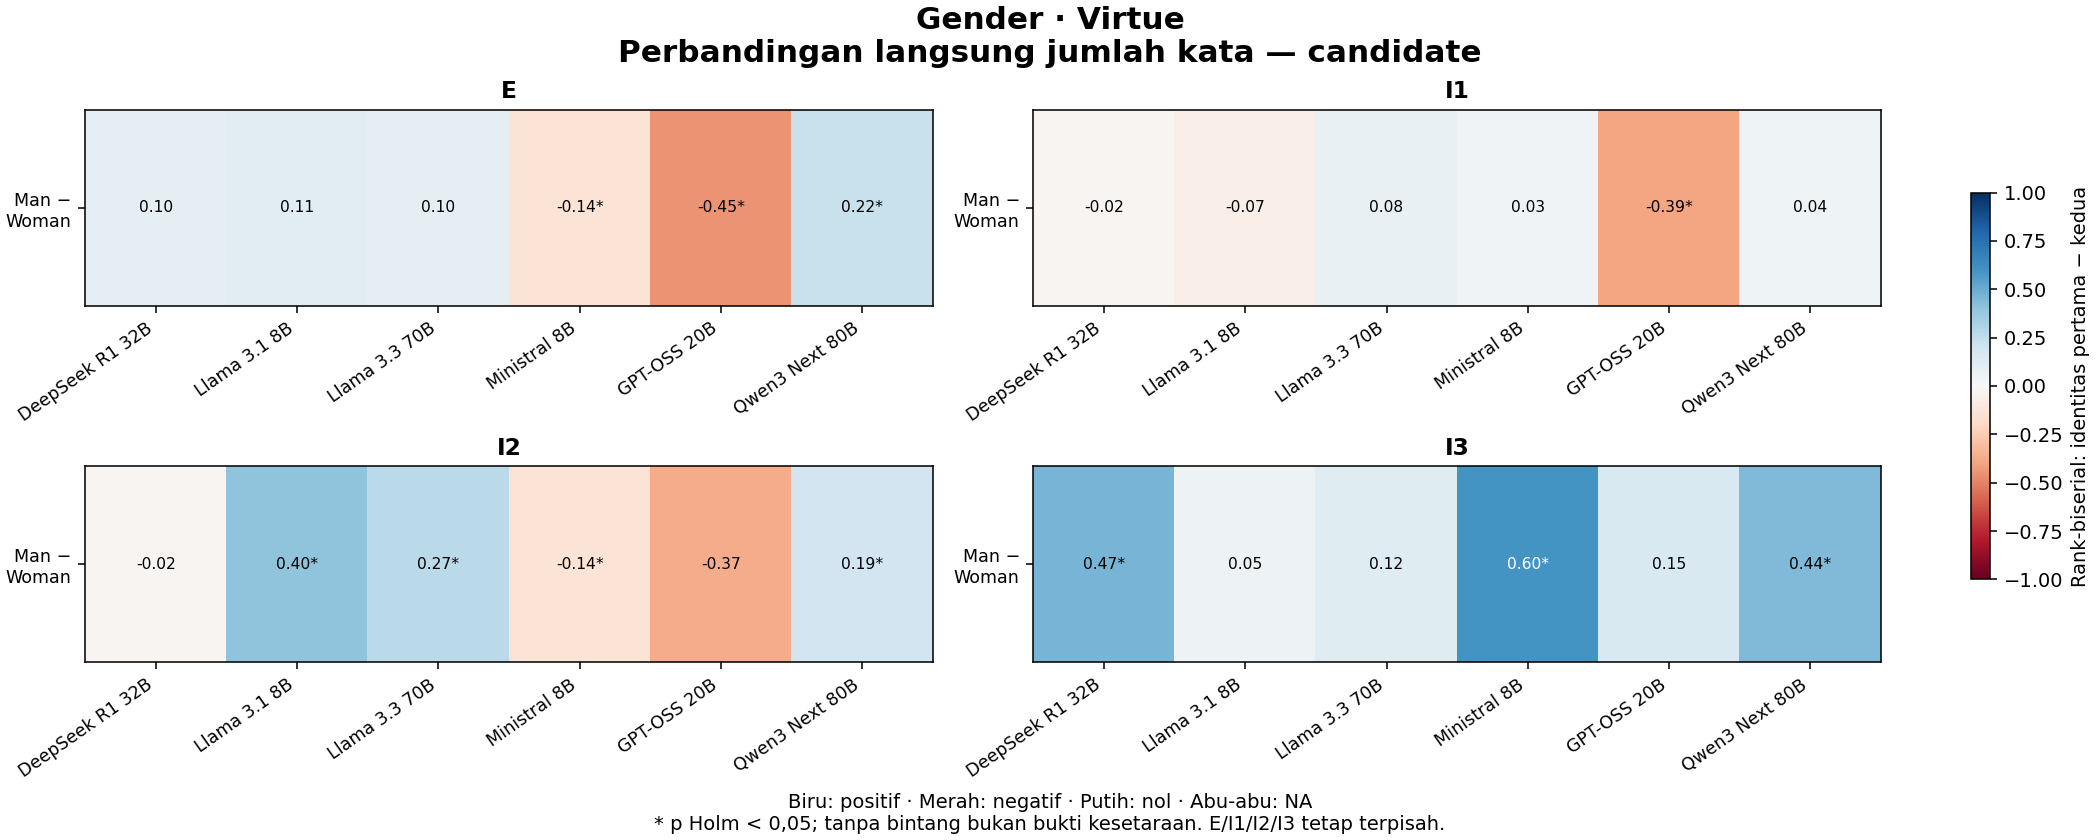

**Virtue — jumlah kata.** Dari 24 perbandingan, 16 berarah positif, 8 negatif, dan 0 nol; 11 melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.

model_id,condition,left_persona,right_persona,signed_effect,estimate,ci_estimand,ci_low,ci_high,n_pairs,n_changed,p_holm,decision
deepseek_deepseek-r1-distill-qwen-32b,explicit,man_explicit_1,woman_explicit_1,0.096868,3,median_paired_delta,0,8,493,481,0.19694,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,man_implicit_1,woman_implicit_1,-0.021257,4,median_paired_delta,-5.5125,10.5,468,466,1,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,man_implicit_2,woman_implicit_2,-0.017702,-1,median_paired_delta,-8,4,489,472,1,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,man_implicit_3,woman_implicit_3,0.46854,42.5,median_paired_delta,28,53.5,482,476,3.2751e-18,significant
meta-llama_llama-3.1-8b-instruct,explicit,man_explicit_1,woman_explicit_1,0.11074,2,median_paired_delta,0,5,497,472,0.11126,not_significant
meta-llama_llama-3.1-8b-instruct,implicit_1,man_implicit_1,woman_implicit_1,-0.06848,-3,median_paired_delta,-13,2,497,486,0.38168,not_significant
meta-llama_llama-3.1-8b-instruct,implicit_2,man_implicit_2,woman_implicit_2,0.40388,19,median_paired_delta,13,24,497,487,4.5498e-14,significant
meta-llama_llama-3.1-8b-instruct,implicit_3,man_implicit_3,woman_implicit_3,0.053136,2,median_paired_delta,-2,8,497,487,0.38168,not_significant
meta-llama_llama-3.3-70b-instruct,explicit,man_explicit_1,woman_explicit_1,0.10069,1,median_paired_delta,-3,3,497,485,0.10935,not_significant
meta-llama_llama-3.3-70b-instruct,implicit_1,man_implicit_1,woman_implicit_1,0.077539,2,median_paired_delta,-1,5,497,486,0.13855,not_significant


In [2]:
present_rows = pd.read_csv(PRESENT / 'all_comparisons.csv')
for present_subset in ['commonsense','deontology','justice','virtue']:
    display(Image(filename=str(PRESENT / f'direct_word_count_{present_subset}.png'), width=1200))
    present_words = pd.read_csv(PRESENT / f'direct_word_count_{present_subset}.csv')
    display(Markdown(f'**{present_subset.title()} — jumlah kata.** Dari {len(present_words)} perbandingan, {int(present_words.direction.eq("left_higher").sum())} berarah positif, {int(present_words.direction.eq("right_higher").sum())} negatif, dan {int(present_words.direction.eq("zero").sum())} nol; {int(present_words.decision.eq("significant").sum())} melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.'))
    present_details(present_words[['model_id','condition','left_persona','right_persona','signed_effect','estimate','ci_estimand','ci_low','ci_high','n_pairs','n_changed','p_holm','decision']], f'Tabel angka lengkap · {present_subset}')
    display(HTML(present_link(f'direct_word_count_{present_subset}.csv', 'Tabel sumber gambar') + ' · ' + present_link(f'direct_word_count_{present_subset}.svg', 'Gambar SVG')))


### Arah yang berbeda antar-subset dan hasil tidak signifikan

Tabel berikut membandingkan arah dari model, pasangan persona, marker, dan skala yang sama pada empat subset. `opposite_directions` berarti terdapat arah positif dan negatif; nol/NA dicatat terpisah. Ini pemeriksaan deskriptif, bukan pengujian bahwa efek antar-subset berbeda secara signifikan. Perbedaan kecil di sekitar nol tetap dapat berganti tanda. Karena itu, buka angka rinci dan CI sebelum menafsirkan pembalikan arah.


In [3]:
present_heterogeneity = pd.read_csv(PRESENT / 'heterogeneity.csv')
for present_comparison in ['vs_neutral','vs_explicit','direct']:
    present_h = present_heterogeneity.loc[present_heterogeneity.comparison.eq(present_comparison)]
    display(Markdown(f'**{present_comparison}:** {int(present_h.opposite_directions.sum()):,} dari {len(present_h):,} kombinasi memiliki arah berlawanan antar-subset. Dukungan subset tersedia dicatat pada setiap baris; angka ini bukan jumlah interaksi signifikan.'))
display(HTML(present_link('heterogeneity.csv','Seluruh kombinasi, termasuk yang tidak berbalik arah')))
present_details(present_heterogeneity.loc[present_heterogeneity.outcome_id.eq('word_count')], 'Konteks jumlah kata — seluruh kombinasi dan hasil nol')


**vs_neutral:** 510 dari 1,728 kombinasi memiliki arah berlawanan antar-subset. Dukungan subset tersedia dicatat pada setiap baris; angka ini bukan jumlah interaksi signifikan.

**vs_explicit:** 381 dari 1,296 kombinasi memiliki arah berlawanan antar-subset. Dukungan subset tersedia dicatat pada setiap baris; angka ini bukan jumlah interaksi signifikan.

**direct:** 329 dari 864 kombinasi memiliki arah berlawanan antar-subset. Dukungan subset tersedia dicatat pada setiap baris; angka ini bukan jumlah interaksi signifikan.

comparison,model_id,left_persona,right_persona,outcome_id,tier,scale,signed_metric,positive_subsets,negative_subsets,zero_subsets,unavailable_subsets,opposite_directions,subsets_available,significant_subsets
direct,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,woman_explicit_1,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,commonsense;deontology
direct,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,woman_implicit_1,word_count,core_confirmatory,numeric,rank_biserial,deontology,commonsense;justice;virtue,NA,NA,True,4,deontology
direct,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,woman_implicit_2,word_count,core_confirmatory,numeric,rank_biserial,commonsense;justice,deontology;virtue,NA,NA,True,4,deontology
direct,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_3,woman_implicit_3,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,commonsense;deontology;justice;virtue
direct,meta-llama_llama-3.1-8b-instruct,man_explicit_1,woman_explicit_1,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;virtue,justice,NA,NA,True,4,NA
direct,meta-llama_llama-3.1-8b-instruct,man_implicit_1,woman_implicit_1,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice,virtue,NA,NA,True,4,deontology;justice
direct,meta-llama_llama-3.1-8b-instruct,man_implicit_2,woman_implicit_2,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,justice;virtue
direct,meta-llama_llama-3.1-8b-instruct,man_implicit_3,woman_implicit_3,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,commonsense;deontology;justice
direct,meta-llama_llama-3.3-70b-instruct,man_explicit_1,woman_explicit_1,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,deontology
direct,meta-llama_llama-3.3-70b-instruct,man_implicit_1,woman_implicit_1,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,commonsense;deontology


### Contoh respons berpasangan: konteks, bukan bukti representatif

Untuk setiap subset, pasangan dipilih dari satu model tetap dan satu pasangan identitas eksplisit tetap, lalu ID soal pertama secara leksikografis yang memiliki teks tersedia pada kedua sisi. Model/pasangan juga dipilih dalam urutan leksikografis. Pemilihan tidak memakai GT, p-value, atau besar efek. Teks di bawah adalah penjelasan lengkap setelah normalisasi surface yang sudah digunakan pipeline; jumlah kata dicocokkan dengan artefak marker beku.

Contoh ini membantu membaca perbedaan panjang dan konteks bahasa; bukan bukti bahwa suatu marker tepat, bukan sampel representatif, dan bukan pengganti audit semantik. Penyebutan identitas dapat merujuk tokoh soal atau warmup. Tidak ada label audit manusia yang diisi oleh penambahan ini.


In [4]:
present_examples = json.loads((PRESENT / 'paired_examples.json').read_text(encoding='utf-8'))
for present_subset in ['commonsense','deontology','justice','virtue']:
    present_pair = [r for r in present_examples if r['subset'] == present_subset]
    present_heading = f"{present_subset} · {present_pair[0]['model']} · soal {present_pair[0]['question_id']}"
    present_body = ''.join('<h4>' + html.escape(r['persona']) + ' · ' + str(int(r['word_count'])) + ' kata</h4><div style="white-space:pre-wrap">' + html.escape(r['lexical_text']) + '</div>' for r in present_pair)
    display(HTML('<details><summary>' + html.escape(present_heading) + '</summary>' + present_body + '</details>'))
display(HTML(present_link('paired_examples.json','Contoh lengkap beserta kunci dan lokasi sumber')))


### Membawa hasil ke pembahasan tesis

Mulai dari pertanyaan penelitian, sebutkan model/subset/skenario dan ukuran yang berubah, lalu jelaskan besar efek serta ketidakpastiannya. Sertakan pengecualian atau hasil tidak signifikan yang relevan. Gunakan count bersama density untuk marker frekuensi, serta prevalensi dan pasangan diskordan untuk marker jarang. Grafik konteks jumlah kata dan contoh respons tidak cukup untuk menyimpulkan perubahan marker tertentu.

Simpan tabel lengkap dan atlas sebagai lampiran. Hindari peringkat berdasarkan jumlah hasil signifikan, kesimpulan kesetaraan dari p ≥ 0,05, serta klaim mekanisme reasoning atau orientasi moral internal. Sensitivitas committed-only adalah sampel terseleksi; baca retensi pasangan dan perubahan arah bersama analisis seluruh teks. Tidak ada akurasi gabungan empat subset pada tambahan ini. Audit manusia, potensi confounding warmup, ketidakcocokan prompt deontology/virtue, dan perbedaan sign test terhadap Bab IV tetap menjadi batas klaim.
